In [144]:
!pip install kagglehub

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [145]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\benmi\.cache\kagglehub\datasets\iammustafatz\diabetes-prediction-dataset\versions\1


In [146]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler


In [147]:
df = pd.read_csv("../datasets/diabetes_prediction_dataset.csv")
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [148]:
print(df.shape)
df.columns


(100000, 9)


Index(['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history',
       'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes'],
      dtype='object')

In [149]:
df.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,41.885856,0.07485,0.039420,27.320767,5.527507,138.058060,0.085000
std,22.516840,0.26315,0.194593,6.636783,1.070672,40.708136,0.278883
min,0.080000,0.00000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,24.000000,0.00000,0.000000,23.630000,4.800000,100.000000,0.000000
50%,43.000000,0.00000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,60.000000,0.00000,0.000000,29.580000,6.200000,159.000000,0.000000
max,80.000000,1.00000,1.000000,95.690000,9.000000,300.000000,1.000000


In [150]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


In [151]:
df.isnull().sum()

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

In [152]:
print(df.duplicated().sum())
df = df.drop_duplicates()
print(df.duplicated().sum())

3854
0


In [153]:
df.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,96146.000000,96146.000000,96146.000000,96146.000000,96146.000000,96146.000000,96146.000000
mean,41.794326,0.077601,0.040803,27.321461,5.532609,138.218231,0.088220
std,22.462948,0.267544,0.197833,6.767716,1.073232,40.909771,0.283616
min,0.080000,0.000000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,24.000000,0.000000,0.000000,23.400000,4.800000,100.000000,0.000000
50%,43.000000,0.000000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,59.000000,0.000000,0.000000,29.860000,6.200000,159.000000,0.000000
max,80.000000,1.000000,1.000000,95.690000,9.000000,300.000000,1.000000


# PLOTS

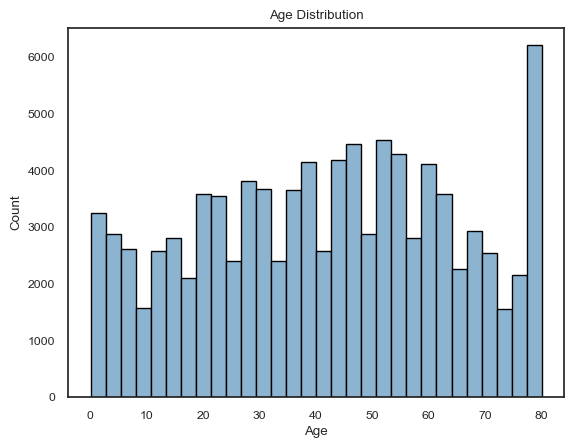

In [154]:
plt.hist(df['age'], bins=30, edgecolor='black')
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

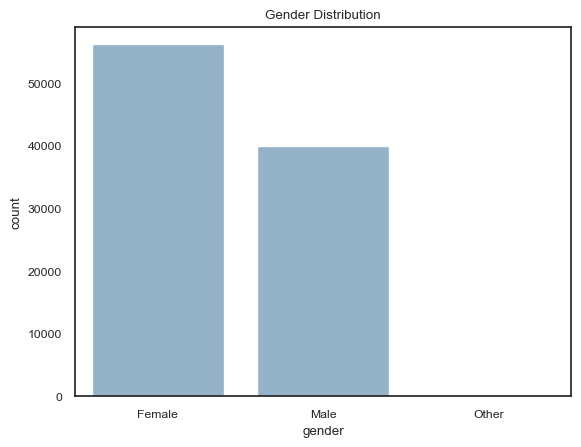

In [155]:
sns.countplot(x='gender', data=df)
plt.title('Gender Distribution')
plt.show()

C:\Users\benmi\AppData\Local\Temp\ipykernel_33444\3915194543.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['bmi'], bins=30)


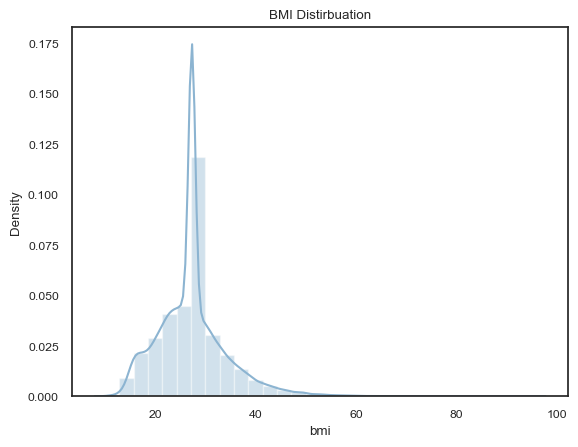

In [156]:
sns.distplot(df['bmi'], bins=30)
plt.title('BMI Distirbuation')
plt.show()


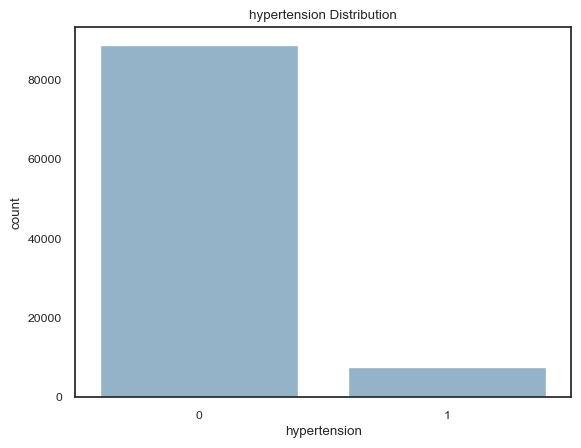

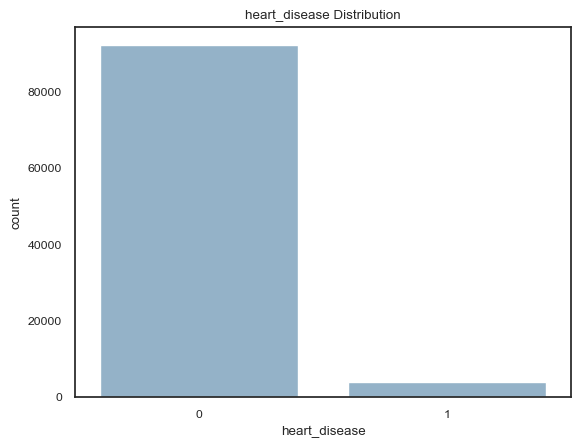

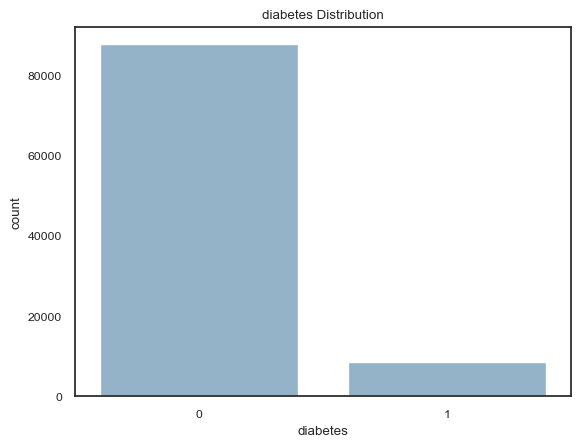

In [157]:
for col in ['hypertension', 'heart_disease' , 'diabetes']:
    sns.countplot(x=col , data=df )
    plt.title(f'{col} Distribution')
    plt.show()

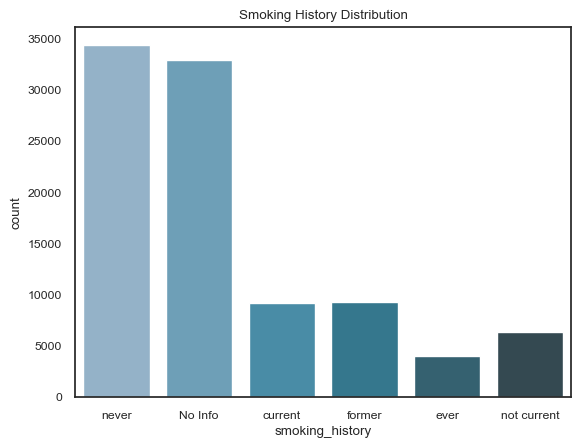

In [158]:
sns.countplot(
    x='smoking_history',
    data=df,
    hue='smoking_history',
    legend=False,
)
plt.title('Smoking History Distribution')
plt.show()

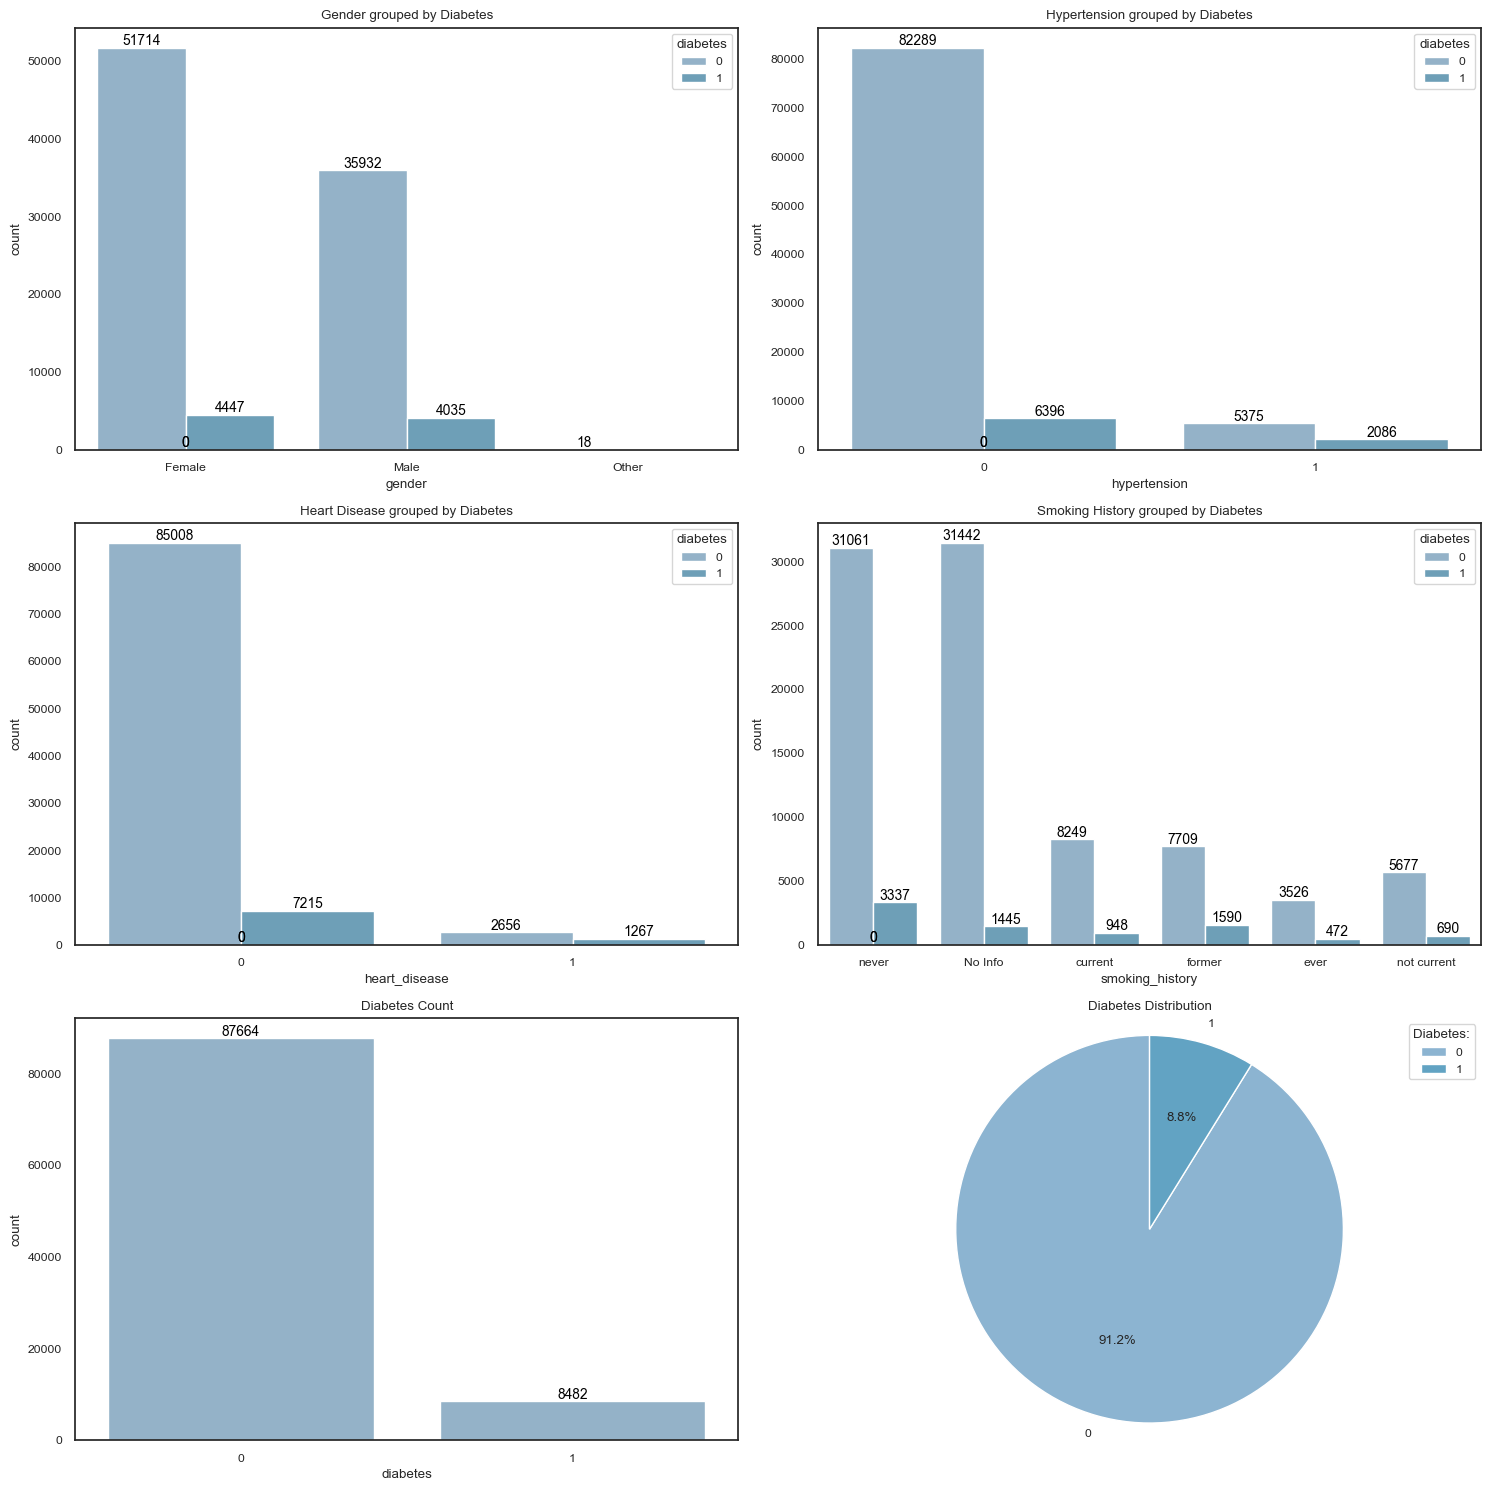

In [159]:
# Function to add counts on bars
def add_counts(ax):
    for p in ax.patches:
        ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()), 
                    ha='center', va='center', fontsize=10, color='black', xytext=(0, 5), 
                    textcoords='offset points')

# Set up the matplotlib figure
fig, axes = plt.subplots(3, 2, figsize=(15, 15))

# Plot gender grouped by diabetes
ax = sns.countplot(ax=axes[0, 0], x='gender', hue='diabetes', data=df)
axes[0, 0].set_title('Gender grouped by Diabetes')
add_counts(ax)

# Plot hypertension grouped by diabetes
ax = sns.countplot(ax=axes[0, 1], x='hypertension', hue='diabetes', data=df)
axes[0, 1].set_title('Hypertension grouped by Diabetes')
add_counts(ax)

# Plot heart disease grouped by diabetes
ax = sns.countplot(ax=axes[1, 0], x='heart_disease', hue='diabetes', data=df)
axes[1, 0].set_title('Heart Disease grouped by Diabetes')
add_counts(ax)

# Plot smoking history grouped by diabetes
ax = sns.countplot(ax=axes[1, 1], x='smoking_history', hue='diabetes', data=df)
axes[1, 1].set_title('Smoking History grouped by Diabetes')
add_counts(ax)

# Plot diabetes
ax = sns.countplot(ax=axes[2, 0], x='diabetes', data=df)
axes[2, 0].set_title('Diabetes Count')
add_counts(ax)

# Create pie plot for diabetes
diabetes_counts = df['diabetes'].value_counts()
axes[2, 1].pie(diabetes_counts, labels=diabetes_counts.index, autopct='%1.1f%%', startangle=90)
axes[2, 1].set_title('Diabetes Distribution')
axes[2, 1].axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
axes[2, 1].legend(title='Diabetes:', loc='upper right')
# Adjust the layout
plt.tight_layout()

# Show the plots
plt.show()

Minimum age: 0.08
Maximum age: 80.0
Average age: 41.79432571297818
Diabetes Counts:
diabetes
0    87664
1     8482
Name: count, dtype: int64
Age Statistics by Diabetes Status:
           min   max
diabetes            
0         0.08  80.0
1         3.00  80.0


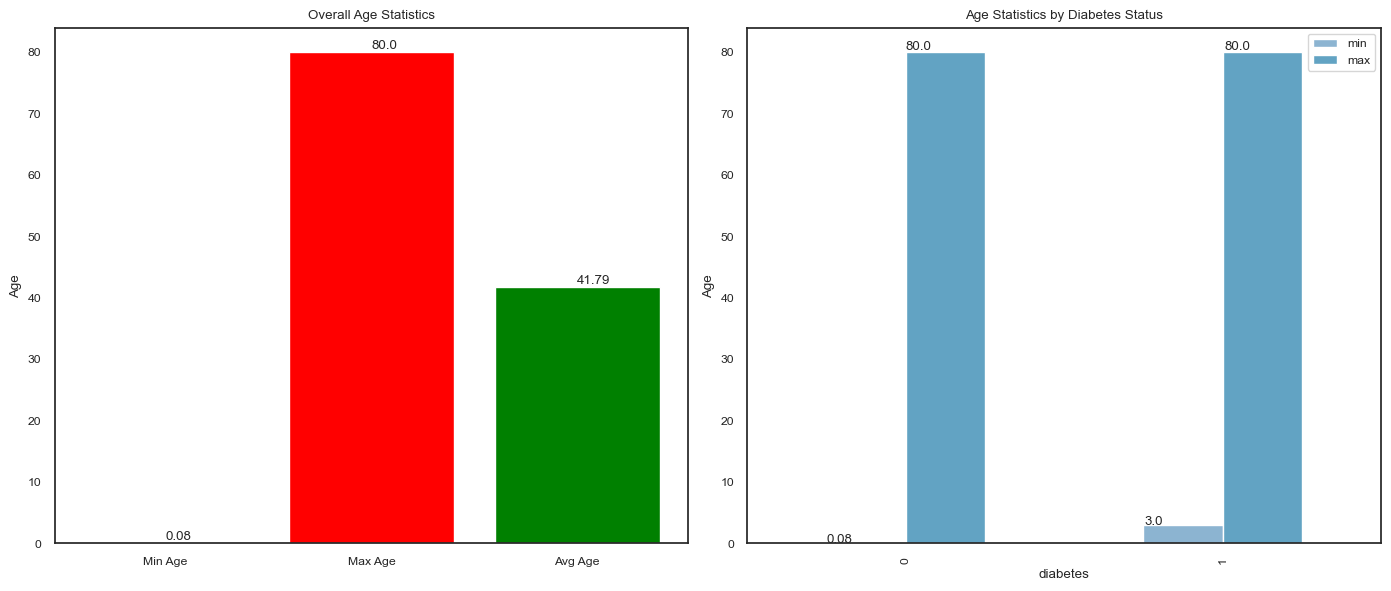

In [160]:
# Calculate minimum, maximum, and average age
min_age = df['age'].min()
max_age = df['age'].max()
avg_age = df['age'].mean()

# Count of individuals with and without diabetes
diabetes_counts = df['diabetes'].value_counts()

# Group by diabetes status and calculate min and max ages
grouped_ages = df.groupby('diabetes')['age'].agg(['min', 'max'])

# Print the results
print(f"Minimum age: {min_age}")
print(f"Maximum age: {max_age}")
print(f"Average age: {avg_age}")
print("Diabetes Counts:")
print(diabetes_counts)
print("Age Statistics by Diabetes Status:")
print(grouped_ages)

# Plotting
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

# Plot for overall min, max, and average age
bars = ax[0].bar(['Min Age', 'Max Age', 'Avg Age'], [min_age, max_age, avg_age], color=['blue', 'red', 'green'])
ax[0].set_title('Overall Age Statistics')
ax[0].set_ylabel('Age')

# Annotate bars with their values
for bar in bars:
    yval = bar.get_height()
    ax[0].text(bar.get_x() + bar.get_width()/2, yval, round(yval, 2), va='bottom')  # Add text to the top of the bars

# Plot for min and max ages grouped by diabetes status
grouped_bars = grouped_ages.plot(kind='bar', ax=ax[1])
ax[1].set_title('Age Statistics by Diabetes Status')
ax[1].set_ylabel('Age')

# Annotate bars with their values
for p in grouped_bars.patches:
    grouped_bars.annotate(str(p.get_height()), (p.get_x() * 1.005, p.get_height() * 1.005))

plt.tight_layout()
plt.show()

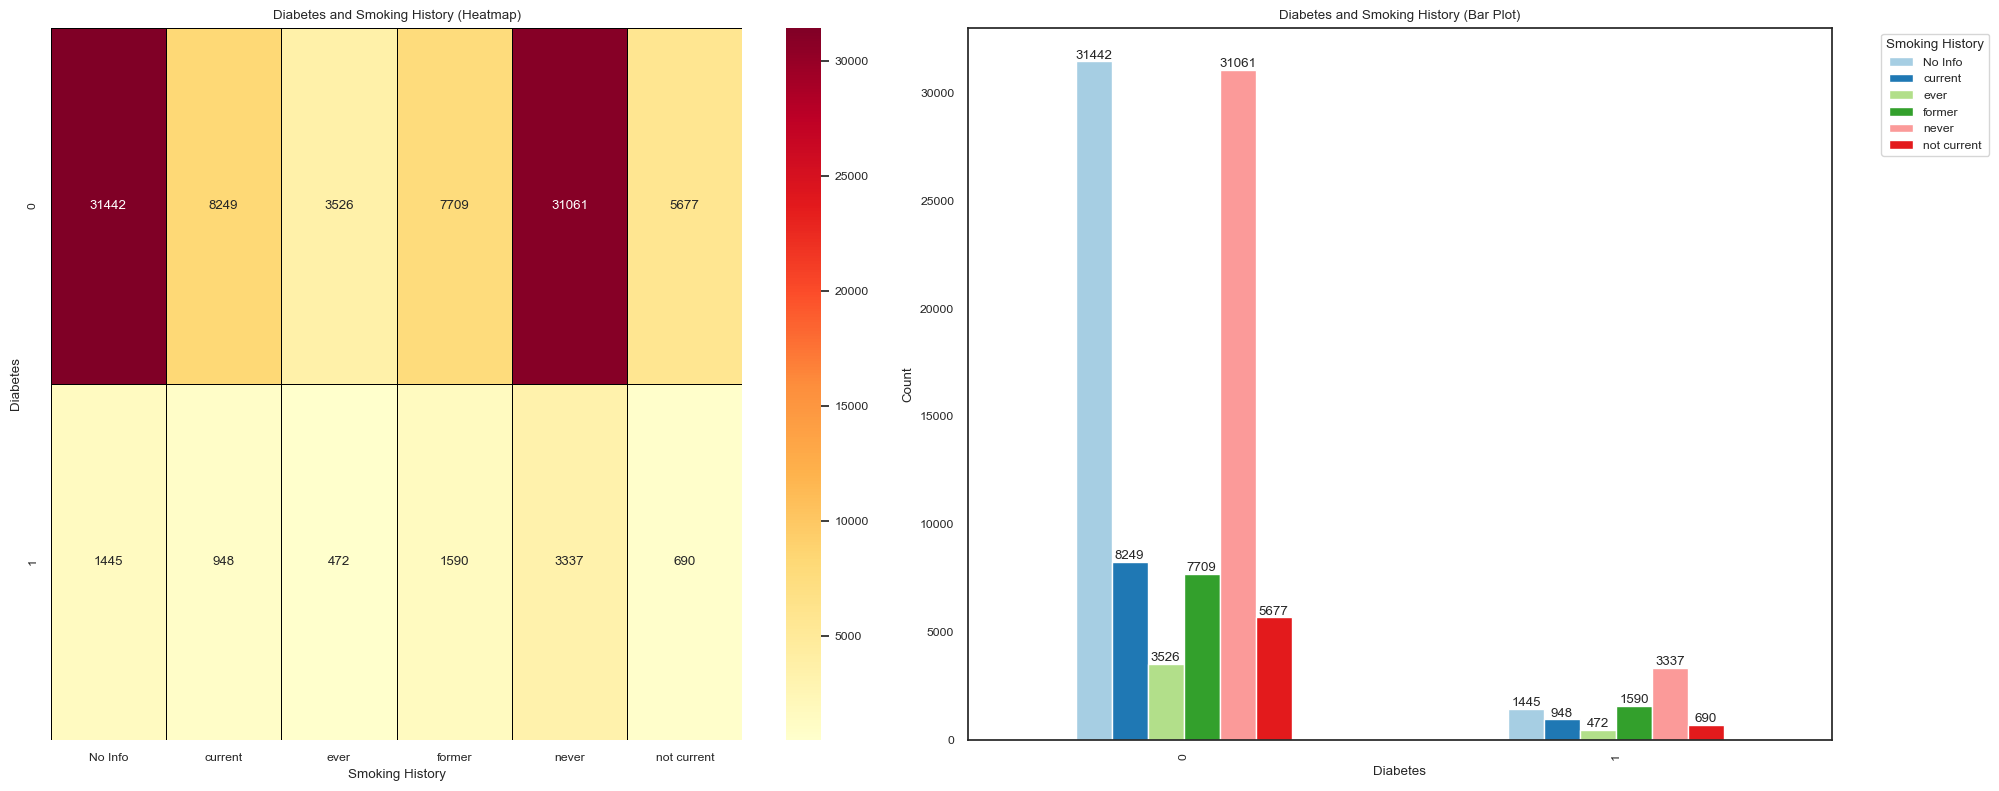

In [161]:
cross_table = pd.crosstab(df['diabetes'], df['smoking_history'])

# Create subplots
fig, ax = plt.subplots(1, 2, figsize=(20, 8))

# Plotting the cross table as a heatmap
sns.heatmap(cross_table, cmap='YlOrRd', annot=True, fmt='d', linewidths=0.5, linecolor='black', ax=ax[0])
ax[0].set_title('Diabetes and Smoking History (Heatmap)')
ax[0].set_xlabel('Smoking History')
ax[0].set_ylabel('Diabetes')

# Plotting the cross table with separate bars for smoking history
cross_table.plot(kind='bar', stacked=False, ax=ax[1], color=plt.cm.Paired.colors)
ax[1].set_title('Diabetes and Smoking History (Bar Plot)')
ax[1].set_xlabel('Diabetes')
ax[1].set_ylabel('Count')
ax[1].legend(title='Smoking History', bbox_to_anchor=(1.05, 1), loc='upper left')

# Annotate bars with their values
for container in ax[1].containers:
    ax[1].bar_label(container)

plt.tight_layout()
plt.show()

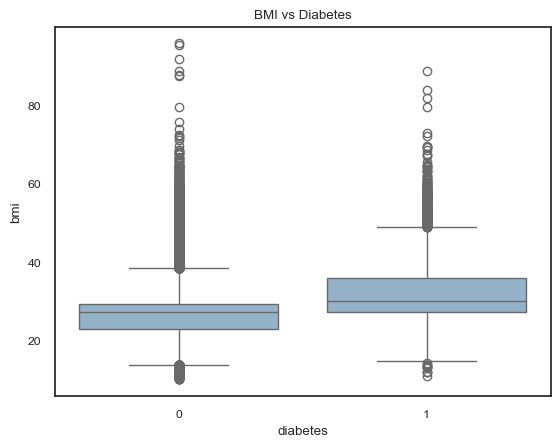

In [162]:
sns.boxplot(x='diabetes', y='bmi', data=df)
plt.title("BMI vs Diabetes")
plt.show()

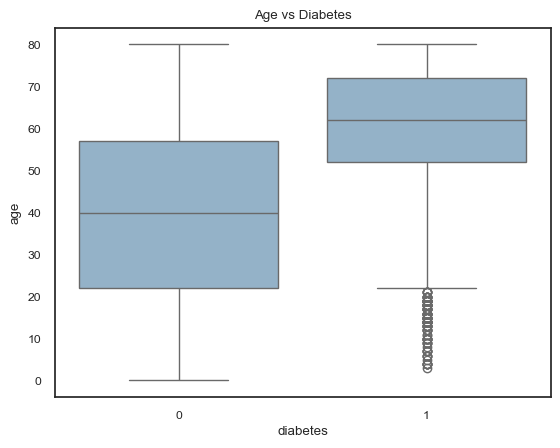

In [163]:
sns.boxplot(x='diabetes', y='age', data=df)
plt.title('Age vs Diabetes')
plt.show()

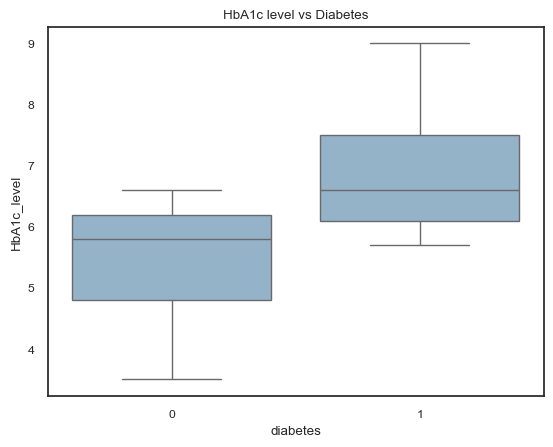

In [164]:
sns.boxplot(x='diabetes', y='HbA1c_level', data=df)
plt.title('HbA1c level vs Diabetes')
plt.show()

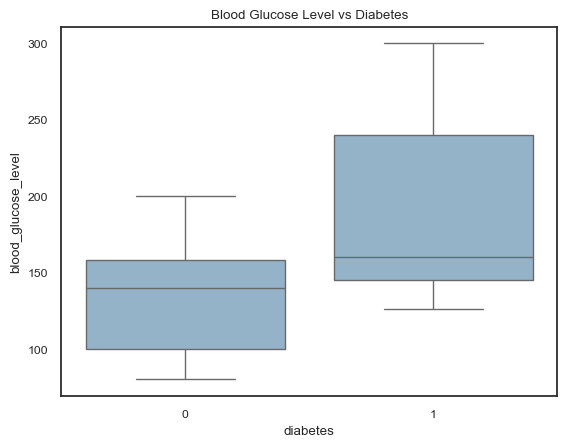

In [165]:
sns.boxplot(x='diabetes', y='blood_glucose_level', data=df)
plt.title('Blood Glucose Level vs Diabetes')
plt.show()

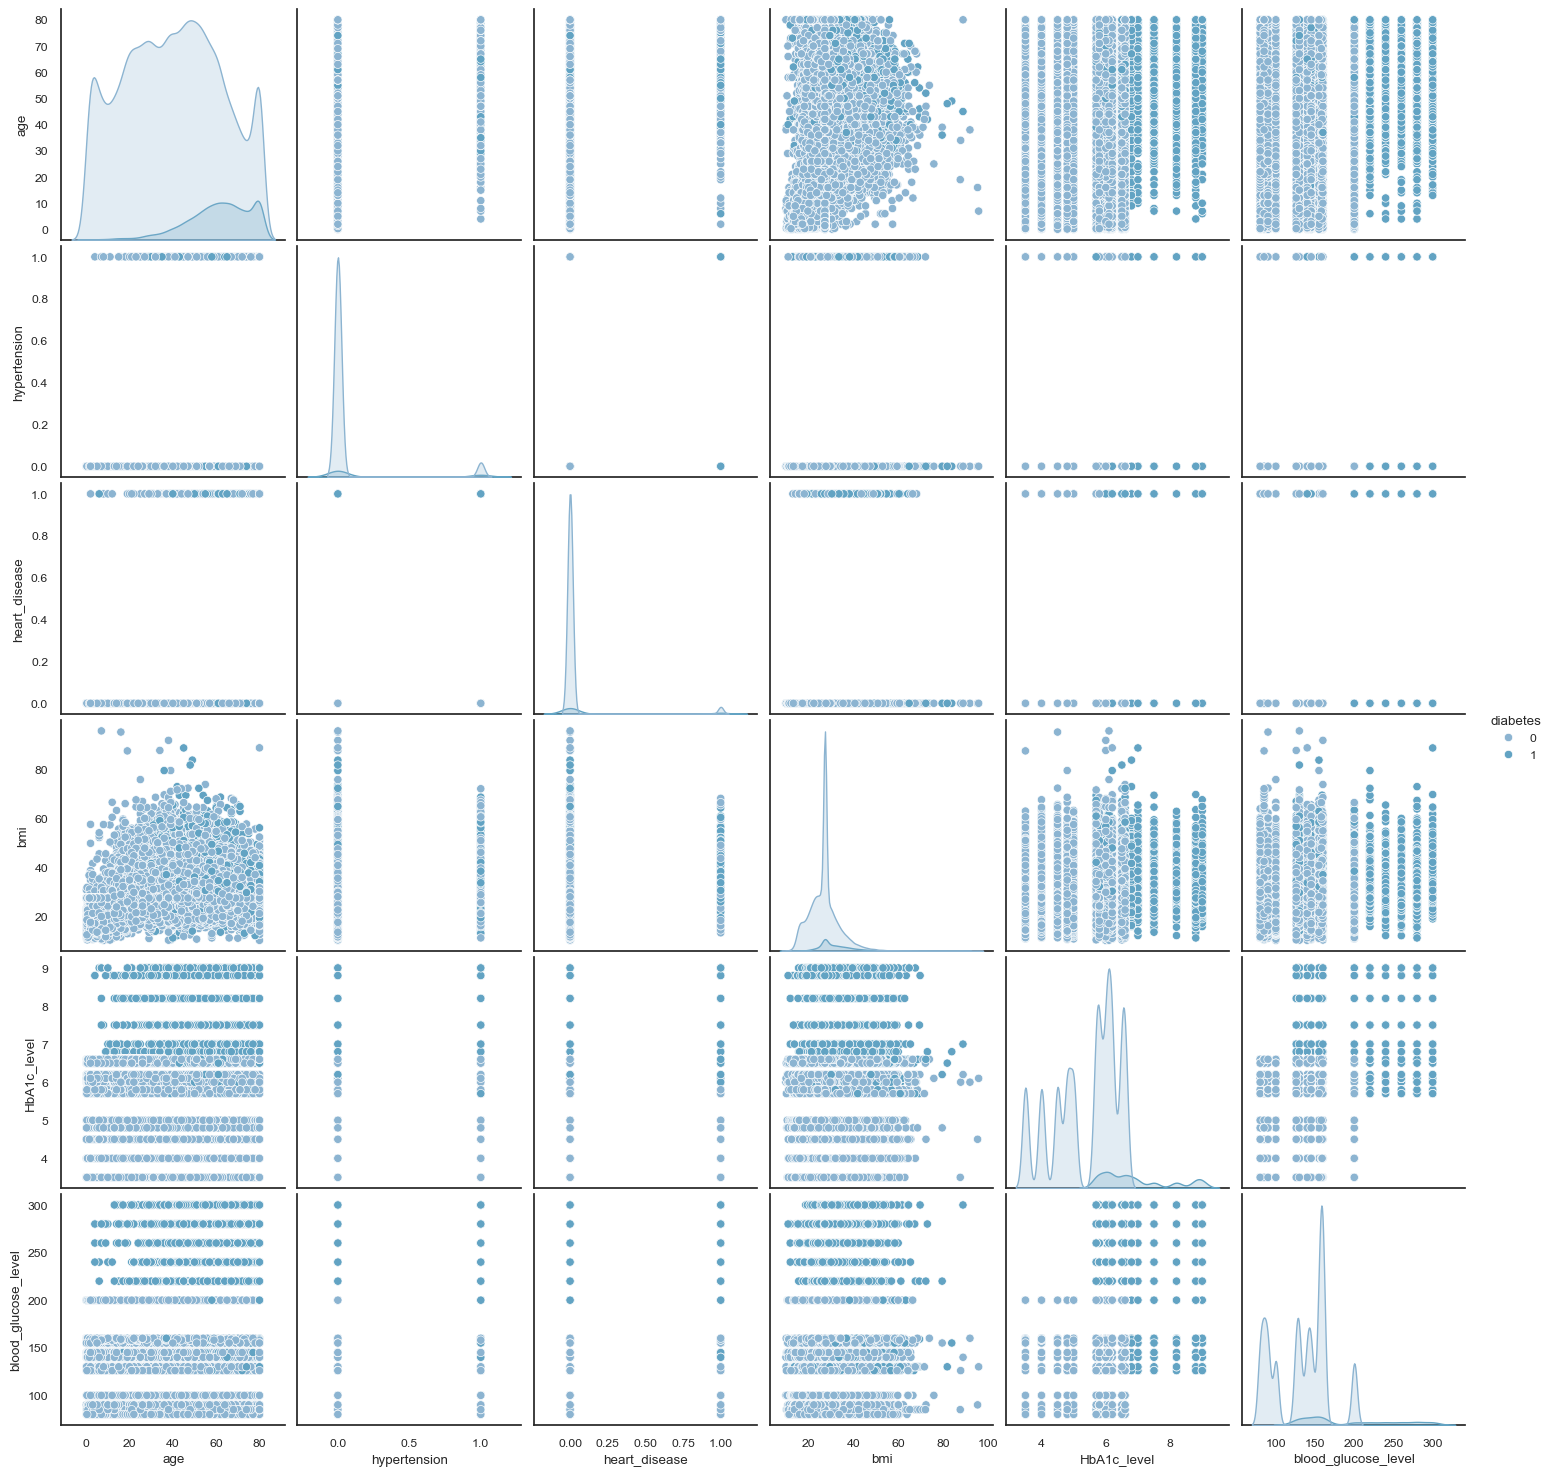

In [166]:
sns.pairplot(df,hue='diabetes')
plt.show()

In [167]:
df['gender'].unique()

array(['Female', 'Male', 'Other'], dtype=object)

In [168]:
print(df['gender'].value_counts().unique())

[56161 39967    18]


In [169]:
# Drops rows where gender is exactly 'others'
df = df[df['gender'] != 'Other']


In [170]:
print(df['gender'].value_counts().unique())
df['gender'].unique()

[56161 39967]


array(['Female', 'Male'], dtype=object)

In [171]:
# Define a function to map the existing categories to new ones
def recategorize_smoking(smoking_status):
    if smoking_status in ['never', 'No Info']:
        return 'non-smoker'
    elif smoking_status == 'current':
        return 'current'
    elif smoking_status in ['ever', 'former', 'not current']:
        return 'past_smoker'

# Apply the function to the 'smoking_history' column
df['smoking_history'] = df['smoking_history'].apply(recategorize_smoking)

# Check the new value counts
print(df['smoking_history'].value_counts())

smoking_history
non-smoker     67276
past_smoker    19655
current         9197
Name: count, dtype: int64


In [172]:
data = df.copy()

In [173]:
# incode the data
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
data['gender'] = le.fit_transform(data['gender'])
data['smoking_history'] = le.fit_transform(data['smoking_history'])

In [174]:
print(data['smoking_history'].unique())
print(data['gender'].unique())

[1 0 2]
[0 1]


In [190]:
data.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,0,80.0,0,1,1,25.19,6.6,140,0
1,0,54.0,0,0,1,27.32,6.6,80,0
2,1,28.0,0,0,1,27.32,5.7,158,0
3,0,36.0,0,0,0,23.45,5.0,155,0
4,1,76.0,1,1,0,20.14,4.8,155,0


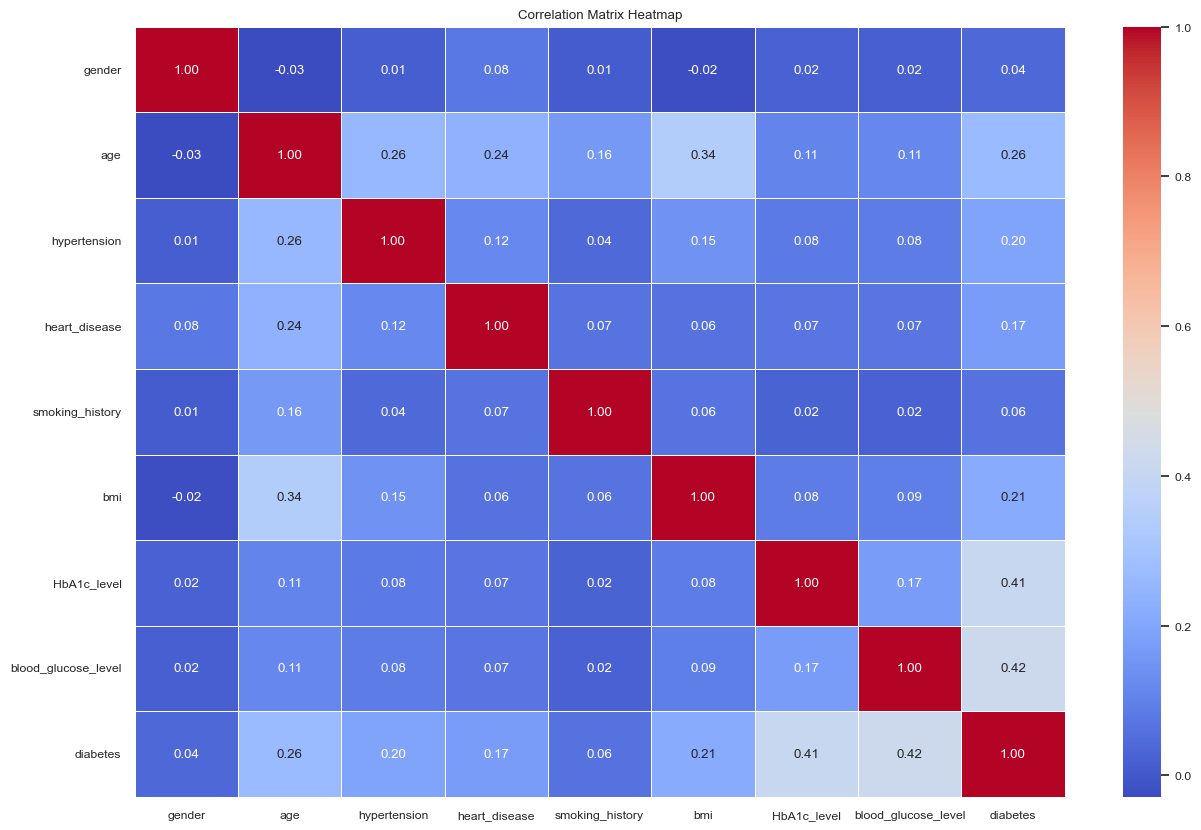

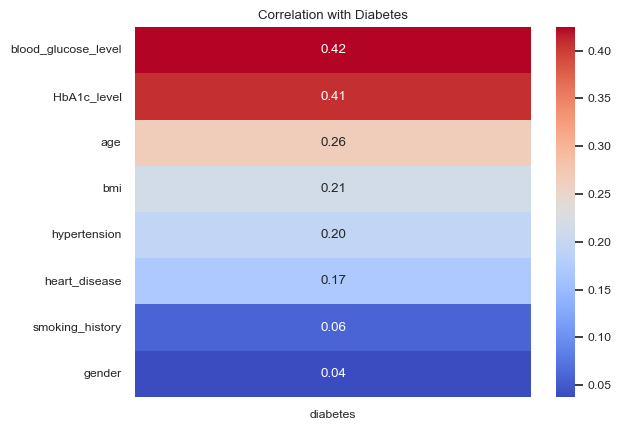

In [176]:
# Compute the correlation matrix
correlation_matrix = data.corr()
#Graph I.
plt.figure(figsize=(15, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', linewidths=0.5, fmt='.2f')
plt.title("Correlation Matrix Heatmap")
plt.show()


#Graph II
# Create a heatmap of the correlations with the target column
corr = data.corr()
target_corr = corr['diabetes'].drop('diabetes')

# Sort correlation values in descending order
target_corr_sorted = target_corr.sort_values(ascending=False)

sns.set(font_scale=0.8)
sns.set_style("white")
sns.set_palette("PuBuGn_d")
sns.heatmap(target_corr_sorted.to_frame(), cmap="coolwarm", annot=True, fmt='.2f')
plt.title('Correlation with Diabetes')
plt.show()

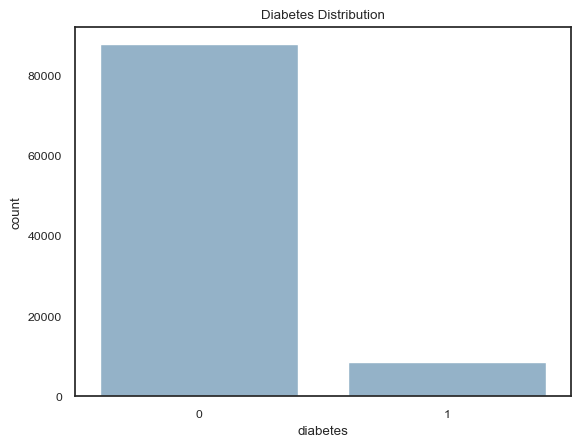

In [177]:
sns.countplot(x='diabetes', data=df)
plt.title('Diabetes Distribution')
plt.show()

In [178]:
df.columns

Index(['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history',
       'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes'],
      dtype='object')

In [191]:
X = data.drop(columns=['diabetes'])
y = data['diabetes']

In [192]:
print(X.shape)
print(y.shape)


(96128, 8)
(96128,)


In [181]:
!pip install imblearn
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [203]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,random_state=42,
stratify=y)
X_train.shape

(76902, 8)

In [204]:
print(type(X_train))
print(type(X_test))
print(X_train.shape)
print(X_test.shape)

<class 'pandas.core.frame.DataFrame'>
<class 'pandas.core.frame.DataFrame'>
(76902, 8)
(19226, 8)


In [207]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [208]:
sm = SMOTE(random_state=42)
X_train_res, y_train_res = sm.fit_resample(X_train_scaled, y_train)

In [211]:
# 1. Count
print(pd.Series(y_train_res).value_counts())

# 2. Percentage
print(pd.Series(y_train_res).value_counts(normalize=True) * 100)

diabetes
0    70116
1    70116
Name: count, dtype: int64
diabetes
0    50.0
1    50.0
Name: proportion, dtype: float64


In [212]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

In [225]:

# Initializing and training the XGBoost model
xgb_model = XGBClassifier(random_state=42)
xgb_model.fit(X_train, y_train)

# Making predictions
y_pred = xgb_model.predict(X_test)

# Evaluating the model
accuracy = accuracy_score(y_test, y_pred)
print(f'XGBoost Accuracy: {accuracy:.4f}')
print(f'XGBoost Classification Report:\n{classification_report(y_test, y_pred)}')

XGBoost Accuracy: 0.9699
XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     17530
           1       0.94      0.70      0.80      1696

    accuracy                           0.97     19226
   macro avg       0.96      0.85      0.89     19226
weighted avg       0.97      0.97      0.97     19226



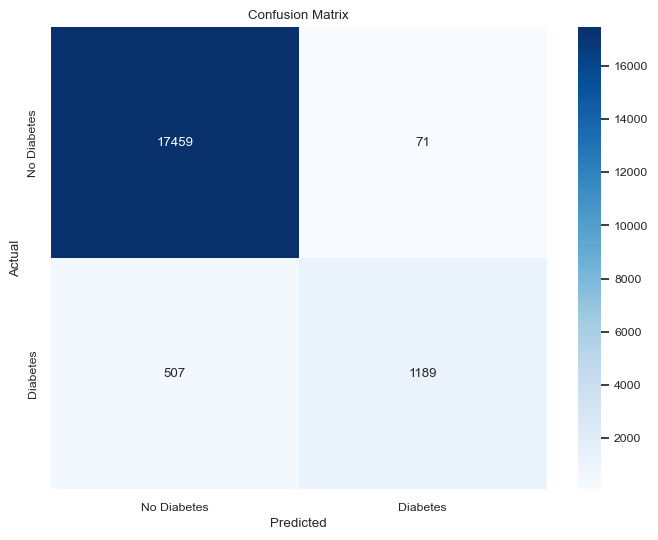

In [226]:
conf_matrix = confusion_matrix(y_test, y_pred)

# Plotting the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['No Diabetes', 'Diabetes'], yticklabels=['No Diabetes', 'Diabetes'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

scale_pos_weight: 10.33
=== scale_pos_weight ===
              precision    recall  f1-score   support

           0       1.00      0.82      0.90     17530
           1       0.35      0.97      0.51      1696

    accuracy                           0.84     19226
   macro avg       0.67      0.90      0.71     19226
weighted avg       0.94      0.84      0.87     19226



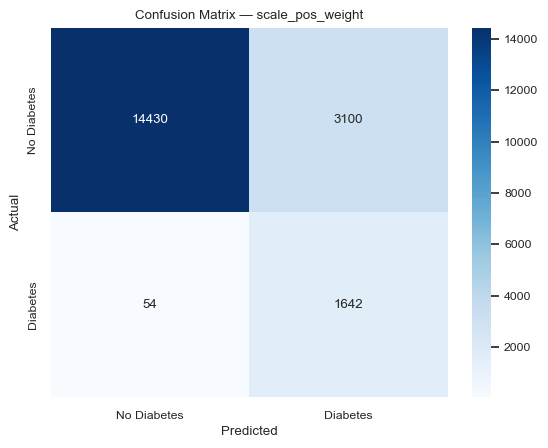

In [240]:
# ── Option 2 — scale_pos_weight ───────────────────────────────────────────────
from xgboost import XGBClassifier

scale_pos_weight = y_train.value_counts()[0] / y_train.value_counts()[1]
print(f"scale_pos_weight: {scale_pos_weight:.2f}")

xgb_weighted = XGBClassifier(
    scale_pos_weight=scale_pos_weight,
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    random_state=42,
    eval_metric='auc'
)

xgb_weighted.fit(X_train_res, y_train_res)

y_pred_weighted = xgb_weighted.predict(X_test_scaled)
y_pred_weighted_proba = xgb_weighted.predict_proba(X_test_scaled)[:, 1]

print("=== scale_pos_weight ===")
print(classification_report(y_test, y_pred_weighted))

cm2 = confusion_matrix(y_test, y_pred_weighted)
sns.heatmap(cm2, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Diabetes', 'Diabetes'],
            yticklabels=['No Diabetes', 'Diabetes'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix — scale_pos_weight')
plt.show()

In [230]:
from sklearn.metrics import classification_report, f1_score

results = []

for spw in [2, 3, 4, 5, 6, 7, 8]:
    model = XGBClassifier(
        scale_pos_weight=spw,
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        random_state=42,
        eval_metric='auc'
    )
    model.fit(X_train_res, y_train_res)
    y_pred = model.predict(X_test_scaled)
    report = classification_report(y_test, y_pred, output_dict=True)
    
    results.append({
        'scale_pos_weight': spw,
        'recall_diabetic':  round(report['1']['recall'], 3),
        'precision_diabetic': round(report['1']['precision'], 3),
        'f1_diabetic':      round(report['1']['f1-score'], 3),
        'accuracy':         round(report['accuracy'], 3)
    })

import pandas as pd
results_df = pd.DataFrame(results)
print(results_df)

   scale_pos_weight  recall_diabetic  precision_diabetic  f1_diabetic  \
0                 2            0.838               0.588        0.691   
1                 3            0.890               0.501        0.641   
2                 4            0.912               0.446        0.599   
3                 5            0.934               0.414        0.573   
4                 6            0.940               0.394        0.555   
5                 7            0.952               0.380        0.543   
6                 8            0.959               0.367        0.531   

   accuracy  
0     0.934  
1     0.912  
2     0.892  
3     0.877  
4     0.867  
5     0.859  
6     0.851  


Optimal threshold: 0.395
              precision    recall  f1-score   support

           0       0.99      0.91      0.95     17530
           1       0.49      0.90      0.63      1696

    accuracy                           0.91     19226
   macro avg       0.74      0.90      0.79     19226
weighted avg       0.95      0.91      0.92     19226



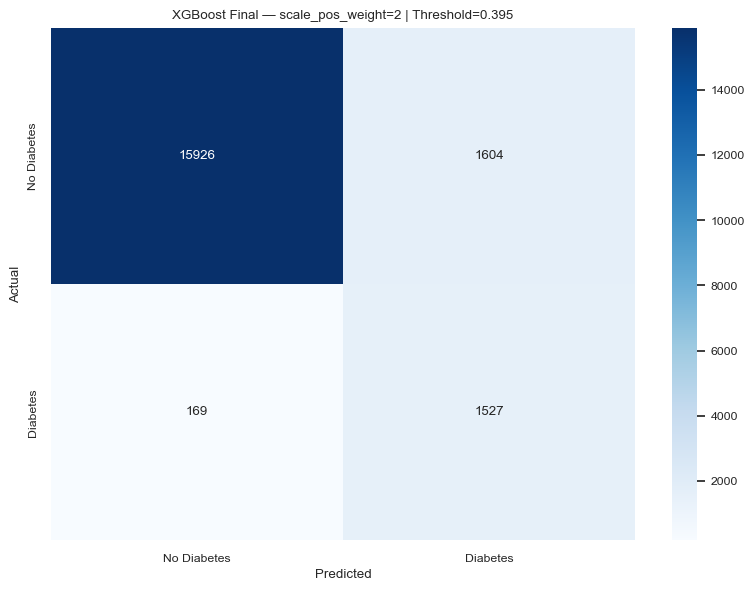

In [232]:
xgb_final = XGBClassifier(
    scale_pos_weight=2,
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    random_state=42,
    eval_metric='auc'
)
xgb_final.fit(X_train_res, y_train_res)

# Find optimal threshold
from sklearn.metrics import roc_curve
import numpy as np

y_proba = xgb_final.predict_proba(X_test_scaled)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
optimal_idx = np.argmax(tpr - fpr)
optimal_threshold = thresholds[optimal_idx]

y_pred_final = (y_proba >= optimal_threshold).astype(int)

print(f"Optimal threshold: {optimal_threshold:.3f}")
print(classification_report(y_test, y_pred_final))
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_final)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Diabetes', 'Diabetes'],
            yticklabels=['No Diabetes', 'Diabetes'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'XGBoost Final — scale_pos_weight=2 | Threshold={optimal_threshold:.3f}')
plt.tight_layout()
plt.show()

In [ ]:
xgb_final.con

In [242]:
import joblib
joblib.dump(xgb_final, 'xgb_diabetes.pkl')
joblib.dump(optimal_threshold, 'xgb_threshold.pkl')
joblib.dump(scaler, 'scaler.pkl')

['scaler.pkl']

In [249]:
X.columns
FEATURES = ['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history',
       'bmi', 'HbA1c_level', 'blood_glucose_level']

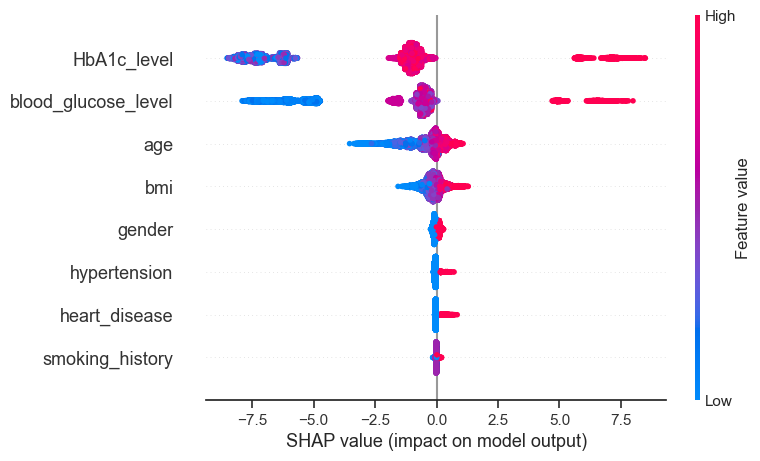

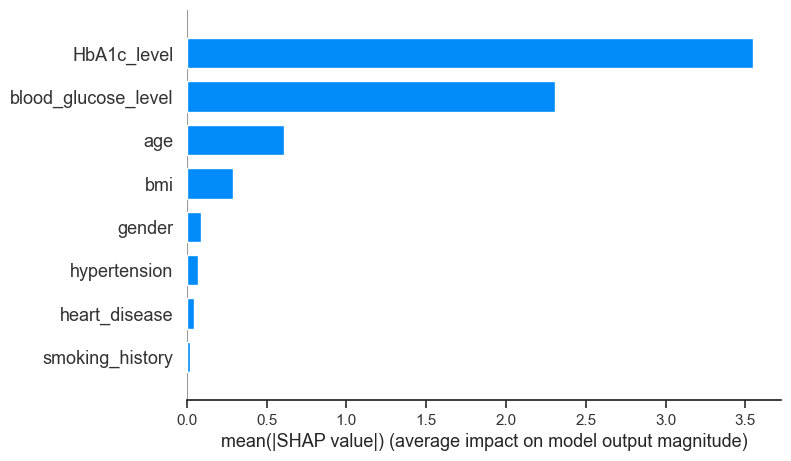

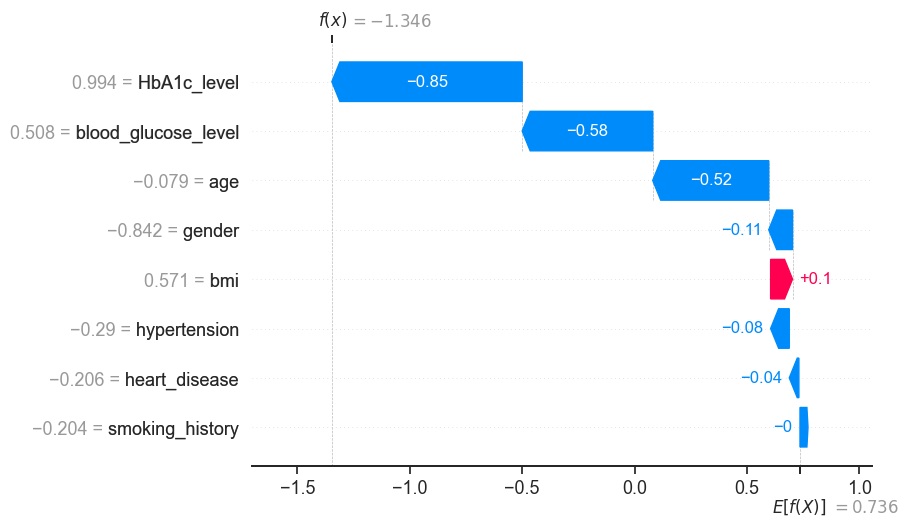

['shap_explainer.pkl']

In [251]:
import shap

# Create explainer
explainer = shap.TreeExplainer(xgb_final)
shap_values = explainer.shap_values(X_test_scaled)

# 1 — Global feature importance
shap.summary_plot(shap_values, X_test_scaled, feature_names=FEATURES)

# 2 — Bar plot (mean absolute SHAP values)
shap.summary_plot(shap_values, X_test_scaled, 
                  feature_names=FEATURES, plot_type='bar')

# 3 — Single patient explanation (first diabetic patient in test set)
diabetic_idx = y_test[y_test == 1].index[0]
pos = list(y_test.index).index(diabetic_idx)

shap.waterfall_plot(shap.Explanation(
    values=shap_values[pos],
    base_values=explainer.expected_value,
    data=X_test_scaled[pos],
    feature_names=FEATURES
))

# Save explainer for FastAPI
import joblib
joblib.dump(explainer, 'shap_explainer.pkl')